# Momentum vs Mean Reversion in Large Japanese Stocks
**Author:** Silam Shrestha

**Question:** Do past returns predict next month's returns for 30 large Japanese stocks, and does any edge survive transaction costs and an out-of-sample test?

**Two signals tested**
1. **Momentum (12-1):** stocks that rose most over the past 12 months (skipping the latest month) keep rising.
2. **Short-term reversal (1-month):** stocks that fell most last month bounce back.

**Method:** each month, rank the stocks on the signal, buy the top third and sell the bottom third (equal weights), hold one month, subtract trading costs. Build on **2014–2019 (in-sample)**, then check on **2020–2025 (out-of-sample)** without changing anything.

> How to use this notebook: run each cell from top to bottom (Shift + Enter). Read the explanation above each cell first.

## Step 1. Install and import tools
- `yfinance` downloads free historical prices from Yahoo Finance.
- `pandas` handles tables of data, `numpy` does maths, `matplotlib` draws charts.

In [21]:
!pip install yfinance -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Step 2. Choose the stocks and settings
30 large, well-known Japanese companies (Tokyo Stock Exchange tickers end in `.T`).

`COST = 0.0010` means **0.10% cost each time we buy or sell** (fees + price impact). This is a simple, honest assumption.

In [22]:
TICKERS = [
    "7203.T", "6758.T", "9984.T", "8306.T", "6861.T", "9432.T", "8035.T", "6098.T",
    "4063.T", "9983.T", "7974.T", "8316.T", "6501.T", "4502.T", "8058.T", "8001.T",
    "6367.T", "7267.T", "4568.T", "6902.T", "9433.T", "8766.T", "6954.T", "4519.T",
    "6594.T", "7741.T", "6981.T", "8411.T", "2914.T", "4661.T",
]
START, END = "2013-01-01", "2025-12-31"
SPLIT_DATE = "2019-12-31"   # in-sample up to here, out-of-sample after
COST = 0.0010               # 0.10% per unit traded

## Step 3. Download daily prices
`auto_adjust=True` adjusts prices for dividends and stock splits, so returns are correct.

We drop any stock missing more than 10% of days.

In [23]:
raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
prices = raw["Close"].dropna(how="all")
prices = prices.dropna(axis=1, thresh=int(len(prices) * 0.9))

if prices.empty:
    raise RuntimeError("No data downloaded. Check your internet connection and run this cell again.")

print("Stocks kept:", prices.shape[1], "| Days:", prices.shape[0])
print("From", prices.index[0].date(), "to", prices.index[-1].date())
prices.tail()

Stocks kept: 29 | Days: 3198
From 2013-01-04 to 2025-12-30


Ticker,2914.T,4063.T,4502.T,4519.T,4568.T,4661.T,6367.T,6501.T,6594.T,6758.T,...,8035.T,8058.T,8306.T,8316.T,8411.T,8766.T,9432.T,9433.T,9983.T,9984.T
Date,,,,,,,,,,,,,,,,,,,,,
2025-12-24,"5,518.2109","4,846.9209","4,694.6172","8,049.4131","3,237.3176","2,880.4949","19,801.6602","4,930.6821","2,054.0000","3,955.5574",...,"6,533.9434","3,433.7144","2,402.9924","2,445.0037","5,600.9072",294.1040,151.3196,"2,637.4336","55,796.5430","4,371.2896"
2025-12-25,"5,511.5220","4,882.4873","4,694.6172","8,110.7632","3,306.1350","2,897.3923","19,909.7324","4,903.0039","2,059.0000","4,004.1345",...,"6,646.0547","3,444.4692","2,406.3823","2,440.6858","5,585.2241",293.6982,151.7069,"2,648.1191","55,401.3867","4,361.3120"
2025-12-26,"5,502.9224","4,835.0654","4,704.2764","8,189.6401","3,327.4587","2,898.3862","19,944.1191","4,914.8657","2,076.0000","4,010.0828",...,"6,752.2661","3,450.3354","2,407.3511","2,447.4028","5,554.8374",294.3576,153.7400,"2,671.9192","56,576.9844","4,439.8838"
2025-12-29,"5,540.0713","4,849.8848","4,739.0518","8,231.2676","3,266.3955","2,866.0825","19,541.3066","4,872.3599","2,086.0000","3,994.2209",...,"6,732.5972","3,489.4436","2,418.0051","2,456.9985","5,594.0459",296.0315,153.5464,"2,640.3479","55,707.6328","4,474.8042"
2025-12-30,"5,513.6758","4,814.3184","4,670.4678","8,169.8179","3,245.0718","2,880.9919","19,727.9746","4,845.6704","2,132.0000","3,989.2642",...,"6,750.2993","3,506.0649","2,414.6150","2,418.6155","5,587.1846",295.0677,152.6750,"2,631.1191","56,250.9805","4,389.9971"


## Step 4. Look at the data
Each line starts at 1, so we can compare growth. Always look at data before modelling: it catches errors early.

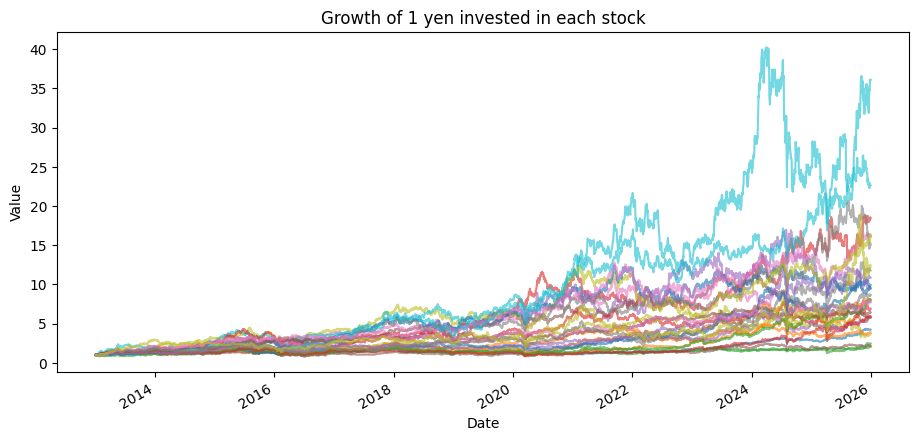

In [24]:
(prices / prices.bfill().iloc[0]).plot(figsize=(11, 5), legend=False, alpha=0.6)
plt.title("Growth of 1 yen invested in each stock")
plt.ylabel("Value")
plt.show()

## Step 5. Monthly prices and returns
- `resample("ME").last()` keeps the **last price of each month**.
- **Return** = (price this month ÷ price last month) − 1.

In [25]:
monthly = prices.resample("ME").last()
rets = monthly.pct_change()
rets.tail()

Ticker,2914.T,4063.T,4502.T,4519.T,4568.T,4661.T,6367.T,6501.T,6594.T,6758.T,...,8035.T,8058.T,8306.T,8316.T,8411.T,8766.T,9432.T,9433.T,9983.T,9984.T
Date,,,,,,,,,,,,,,,,,,,,,
2025-08-31,0.0857,0.0369,0.0526,-0.1156,-0.0513,0.1297,-0.0013,-0.1380,0.1023,0.1089,...,-0.2439,0.1225,0.0704,0.0501,0.0921,0.0452,0.0203,0.0262,0.0086,0.3743
2025-09-30,0.0371,0.0768,-0.0015,-0.0094,-0.0496,0.0156,-0.0730,-0.0237,-0.1799,0.0462,...,0.2884,0.0690,0.0755,0.0509,0.0337,-0.0039,0.0098,-0.0591,-0.0318,0.1526
2025-10-31,0.1035,-0.0408,-0.0375,0.0932,0.1068,-0.1253,0.0524,0.3532,-0.2850,0.0171,...,0.2967,0.0513,-0.0267,-0.0031,0.0323,-0.0777,0.0239,0.0428,0.2580,0.4485
2025-11-30,0.0936,0.0101,0.0850,0.1880,0.0531,-0.0362,0.1285,-0.0658,0.0457,0.0561,...,-0.0696,-0.0027,0.0401,0.1285,0.0629,-0.0472,-0.0164,0.0926,0.0085,-0.3783
2025-12-31,-0.0165,0.0364,0.0730,0.0019,-0.1335,-0.0361,-0.0101,-0.0133,0.0828,-0.1204,...,0.0792,-0.0313,0.0287,0.0730,0.0415,0.0559,0.0122,0.0071,-0.0035,0.0461


## Step 6. Build the two signals
At the end of month *t* we may only use information **known at that time**.

- **Momentum 12-1** = price 1 month ago ÷ price 12 months ago − 1. (We skip the latest month because very short-term returns tend to reverse.)
- **Reversal** = minus last month's return (big losers get a high score).
- **next_ret** = next month's return: what we try to predict.

⚠️ `shift(-1)` looks into the future, so it is used **only as the target**, never inside a signal. Mixing them up is called **look-ahead bias**, the most common backtest mistake.

In [26]:
momentum = monthly.shift(1) / monthly.shift(12) - 1
reversal = -rets
next_ret = rets.shift(-1)

print("Example signals on the last full month:")
pd.DataFrame({"momentum": momentum.iloc[-2], "reversal": reversal.iloc[-2]}).sort_values("momentum").head()

Example signals on the last full month:


,momentum,reversal
Ticker,,
6594.T,-0.3114,-0.0457
4568.T,-0.2120,-0.0531
4063.T,-0.1425,-0.0101
4661.T,-0.1144,0.0362
6861.T,-0.1067,0.0737


## Step 7. Turn a signal into a portfolio
Each month:
1. Rank stocks by the signal.
2. **Buy** the top third (+1/n each), **sell** the bottom third (−1/n each). Money in = money out, so this is **market-neutral**: it tests the signal, not whether the whole market went up.
3. **Turnover** = how much the weights changed since last month. **Cost** = turnover × COST.

In [27]:
def long_short(signal, next_ret, cost=COST, frac=1/3, min_stocks=9):
    weights = pd.DataFrame(0.0, index=signal.index, columns=signal.columns)
    for date in signal.index:
        s = signal.loc[date]
        valid = s.notna() & next_ret.loc[date].notna()
        s = s[valid]
        if len(s) < min_stocks:
            continue
        n = int(len(s) * frac)
        ranked = s.sort_values()
        weights.loc[date, ranked.index[-n:]] = 1.0 / n    # buy top
        weights.loc[date, ranked.index[:n]] = -1.0 / n    # sell bottom
    active = weights.abs().sum(axis=1) > 0
    weights = weights[active]
    gross = (weights * next_ret.loc[weights.index]).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    turnover.iloc[0] = weights.iloc[0].abs().sum()
    net = gross - turnover * cost
    return pd.DataFrame({"gross": gross, "net": net, "turnover": turnover})

results = {"Momentum": long_short(momentum, next_ret), "Reversal": long_short(reversal, next_ret)}
results["Momentum"].head()

,gross,net,turnover
Date,,,
2014-01-31,0.0177,0.0157,2.0000
2014-02-28,-0.0063,-0.0067,0.4444
2014-03-31,-0.0170,-0.0179,0.8889
2014-04-30,-0.0097,-0.0104,0.6667
2014-05-31,0.0087,0.0074,1.3333


## Step 8. Measure performance
- **Annual return** = average monthly return × 12
- **Annual volatility** = monthly standard deviation × √12 (how bumpy)
- **Sharpe ratio** = return ÷ volatility (above about 0.5 is interesting, above 1 is strong)
- **Max drawdown** = worst fall from a peak
- **t-stat** = mean ÷ (sd ÷ √n). Above about 2 suggests the result is unlikely to be pure luck; quant researchers often want 3 because many ideas get tested.
- **Hit rate** = share of months with a positive return

In [28]:
def perf(r):
    r = r.dropna()
    if len(r) < 3:
        return pd.Series(dtype=float)
    cum = (1 + r).cumprod()
    return pd.Series({
        "Months": len(r),
        "Annual return": r.mean() * 12,
        "Annual volatility": r.std() * np.sqrt(12),
        "Sharpe": (r.mean() * 12) / (r.std() * np.sqrt(12)),
        "Max drawdown": (cum / cum.cummax() - 1).min(),
        "t-stat": r.mean() / (r.std() / np.sqrt(len(r))),
        "Hit rate": (r > 0).mean(),
    })

rows = {}
for name, res in results.items():
    for period, mask in [("In-sample 2014-19", res.index <= SPLIT_DATE), ("Out-of-sample 2020-25", res.index > SPLIT_DATE)]:
        rows[(name, period, "net")] = perf(res.loc[mask, "net"])
        rows[(name, period, "gross")] = perf(res.loc[mask, "gross"])
summary = pd.DataFrame(rows).T
summary

Months  Annual return  \
Momentum In-sample 2014-19     net   72.0000        -0.0312   
                               gross 72.0000        -0.0216   
         Out-of-sample 2020-25 net   71.0000         0.0017   
                               gross 71.0000         0.0109   
Reversal In-sample 2014-19     net   83.0000         0.0794   
                               gross 83.0000         0.1140   
         Out-of-sample 2020-25 net   71.0000         0.0123   
                               gross 71.0000         0.0455   

                                      Annual volatility  Sharpe  Max drawdown  \
Momentum In-sample 2014-19     net               0.1488 -0.2099       -0.4130   
                               gross             0.1488 -0.1455       -0.3911   
         Out-of-sample 2020-25 net               0.1662  0.0104       -0.2695   
                               gross             0.1662  0.0657       -0.2528   
Reversal In-sample 2014-19     net               0.1301  0.6105       -0.1235   
                               gross             0.1299  0.8778       -0.0996   
         Out-of-sample 2020-25 net               0.1540  0.0801       -0.4263   
                               gross             0.1542  0.2950       -0.3898   

                                      t-stat  Hit rate  
Momentum In-sample 2014-19     net   -0.5140    0.5139  
                               gross -0.3563    0.5139  
         Out-of-sample 2020-25 net    0.0252    0.4930  
                               gross  0.1599    0.5211  
Reversal In-sample 2014-19     net    1.6056    0.5542  
                               gross  2.3085    0.5663  
         Out-of-sample 2020-25 net    0.1948    0.5070  
                               gross  0.7176    0.5493

## Step 9. Plot the results
The dashed line is where out-of-sample starts. A strategy that only works **before** the line was probably overfitted or lucky.

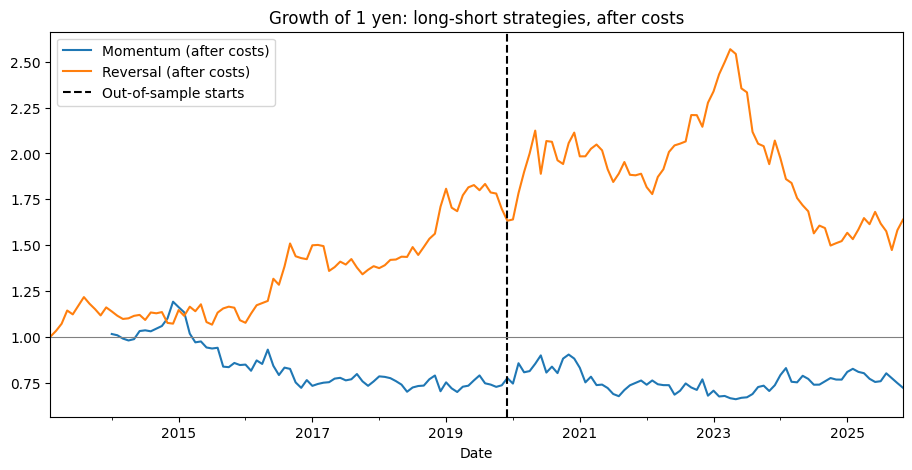

Momentum: average monthly turnover = 0.78
Reversal: average monthly turnover = 2.83


In [29]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, res in results.items():
    (1 + res["net"]).cumprod().plot(ax=ax, label=f"{name} (after costs)")
ax.axvline(pd.Timestamp(SPLIT_DATE), color="black", linestyle="--", label="Out-of-sample starts")
ax.axhline(1, color="grey", linewidth=0.8)
ax.set_title("Growth of 1 yen: long-short strategies, after costs")
ax.legend()
plt.show()

for name, res in results.items():
    print(f"{name}: average monthly turnover = {res['turnover'].mean():.2f}")

## Step 10. Robustness: what if trading costs were higher?
A real edge should not disappear with a small change in assumptions.

In [30]:
rows = {}
for c in [0.0, 0.0005, 0.0010, 0.0020, 0.0040]:
    for name, sig in [("Momentum", momentum), ("Reversal", reversal)]:
        res = long_short(sig, next_ret, cost=c)
        rows[(name, f"{c*100:.2f}% cost")] = perf(res.loc[res.index > SPLIT_DATE, "net"])[["Annual return", "Sharpe", "t-stat"]]
pd.DataFrame(rows).T

,,Annual return,Sharpe,t-stat
Momentum,0.00% cost,0.0109,0.0657,0.1599
Reversal,0.00% cost,0.0455,0.2950,0.7176
Momentum,0.05% cost,0.0063,0.0381,0.0926
Reversal,0.05% cost,0.0289,0.1876,0.4564
Momentum,0.10% cost,0.0017,0.0104,0.0252
Reversal,0.10% cost,0.0123,0.0801,0.1948
Momentum,0.20% cost,-0.0075,-0.0450,-0.1095
Reversal,0.20% cost,-0.0208,-0.1354,-0.3295
Momentum,0.40% cost,-0.0259,-0.1558,-0.3790
Reversal,0.40% cost,-0.0872,-0.5680,-1.3816


## Step 11. Conclusions
1. **Momentum shows no edge in Japanese large caps.** In-sample (2014–19) net Sharpe was −0.21 (t = −0.51); out of sample (2020–25) it was 0.01 (t = 0.03). This is consistent with Asness (2011), "Momentum in Japan: The Exception That Proves the Rule".
2. **Short-term reversal looked promising in-sample but did not hold up.** In-sample gross Sharpe was 0.88 (t = 2.31), but after 0.10% costs it fell to 0.61 (t = 1.61). Out of sample, net Sharpe dropped to 0.08 (gross 0.30).
3. **Costs matter most for high-turnover signals.** Reversal's average monthly turnover was 2.83 vs 0.78 for momentum. Out of sample, both strategies break even at roughly 0.12–0.14% cost per trade, and reversal's Sharpe falls from 0.30 with no costs to 0.08 at 0.10%.

**Conclusion:** neither signal is a robust standalone strategy in this universe. Reversal's in-sample result is a reminder that a t-stat near 2 can fade out of sample.

## Limitations
- **Survivorship bias:** these companies are large *today*. Companies that shrank or disappeared since 2014 are missing.
- **Small universe:** 29 stocks with usable data, so about 9 per side; results are noisy.
- **Simple costs:** a fixed cost ignores market impact and short-selling costs in Japan.
- **Two signals only:** testing more signals would raise the chance of false discoveries.

## Next steps
- Use a larger universe (e.g. TOPIX 500) with historical membership to remove survivorship bias.
- Rank within sectors to remove sector bets.
- Combine signals and test with walk-forward validation.